In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

np.set_printoptions(precision=6, suppress=True)

In [2]:
results = Path("../../results/implementation")
figures = results/"figures"
tables = results/"tables"

In [3]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (414, 8)


,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012,December,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013,August,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013,July,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012,November,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features = [
    "X1 transaction month"
]

target = "Y house price of unit area"

X_df = pd.get_dummies(
    df[numerical_features + categorical_features],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

X = X_df.to_numpy(dtype=float)

y = df[target].to_numpy(dtype=float)

feature_names = ["Intercept"] + X_df.columns.tolist()

x_design = np.column_stack([
    np.ones(X.shape[0]),
    X
])

print("Predictor matrix shape:", X.shape)
print("Design matrix shape:", x_design.shape)
print("Target shape:", y.shape)

print("Number of features including intercept:", len(feature_names))

Predictor matrix shape: (414, 16)
Design matrix shape: (414, 17)
Target shape: (414,)
Number of features including intercept: 17



## Singular Value Decomposition

The design matrix is decomposed as:

\[
X=U\Sigma V^T
\]

The singular values describe the scaling of the design matrix along its principal orthogonal directions.

The SVD decomposition is performed using NumPy's numerical linear algebra implementation.

In [5]:
U, singular_values, Vt = np.linalg.svd(
    x_design,
    full_matrices=False
)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("Vt shape:", Vt.shape)

print("\nSingular values:")
print(singular_values)

U shape: (414, 17)
Singular values shape: (17,)
Vt shape: (17, 17)

Singular values:
[33867.718371  1933.179177   229.172926    47.578029     7.406619
     6.626126     6.469479     5.954132     5.486261     5.424706
     5.294095     5.212729     5.031603     4.826115     1.624628
     0.200364     0.001421]



## Verification of SVD Decomposition

The correctness of the SVD factorization is examined by reconstructing the original design matrix.

The reconstruction condition is:

\[
X\approx U\Sigma V^T
\]

The orthogonality properties of the singular vector matrices are also verified:

\[
U^TU\approx I
\]

\[
V^TV\approx I
\]


In [9]:
Sigma = np.diag(singular_values)

x_reconstructed = U @ Sigma @ Vt

reconstruction_error_svd = np.linalg.norm(
    x_design - x_reconstructed
)

orthogonality_error_U = np.linalg.norm(
    U.T @ U - np.eye(U.shape[1])
)

orthogonality_error_V = np.linalg.norm(
    Vt @ Vt.T - np.eye(Vt.shape[0])
)

print("Reconstruction error:", reconstruction_error_svd)

print("U orthogonality error:", orthogonality_error_U)

print("V orthogonality error:", orthogonality_error_V)

Reconstruction error: 1.698658012739979e-11
U orthogonality error: 3.954998347495161e-15
V orthogonality error: 5.289968096642461e-15



## OLS Coefficient Estimation Using SVD

Using the SVD factorization:

\[
X=U\Sigma V^T
\]

the least-squares solution for a full-column-rank design matrix is:

\[
\hat{\beta}=V\Sigma^{-1}U^Ty
\]

The coefficients are calculated by projecting the target onto the left singular vectors, dividing by the corresponding singular values, and transforming the result using the right singular vectors.

The singular values are examined separately in the pseudoinverse section to investigate numerical tolerance and rank determination.


In [10]:
beta_svd = Vt.T @ ((U.T @ y) / singular_values)

coefficients_svd = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": beta_svd
})

display(coefficients_svd)

,Feature,Coefficient
0,Intercept,-4297.651398
1,X2 house age,-0.272789
2,X3 distance to the nearest MRT station,-0.004482
3,X4 number of convenience stores,1.153752
4,X5 latitude,233.004458
5,X6 longitude,-12.153850
6,X1 transaction month_August,2.835504
7,X1 transaction month_December,-3.014805
8,X1 transaction month_February,0.752765
9,X1 transaction month_January,-0.885104


In [11]:
# predictions and residuals

y_pred_svd = x_design @ beta_svd

residuals_svd = y - y_pred_svd

print("First 10 predictions:")
print(y_pred_svd[:10])

print("\nFirst 10 residuals:")
print(residuals_svd[:10]) 

First 10 predictions:
[45.725401 46.381414 49.768741 50.428735 46.657258 32.146685 39.745188
 44.235186 10.819943 32.003284]

First 10 residuals:
[-7.825401 -4.181414 -2.468741  4.371265 -3.557258 -0.046685  0.554812
  2.464814  7.980057 -9.903284]



## Regression Performance Evaluation

The performance of the OLS model obtained through SVD is evaluated using standard regression metrics.

The following measures are considered:

- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- Coefficient of Determination (R²)

These metrics quantify the prediction errors and the proportion of variation in the target variable explained by the regression model.


In [12]:
mse_svd = mean_squared_error(y, y_pred_svd)
rmse_svd = np.sqrt(mse_svd)
mae_svd = mean_absolute_error(y, y_pred_svd)
r2_svd = r2_score(y, y_pred_svd)

metrics_svd = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2"],
    "SVD": [
        mse_svd,
        rmse_svd,
        mae_svd,
        r2_svd
    ]
})

display(metrics_svd)

,Metric,SVD
0,MSE,74.973033
1,RMSE,8.658697
2,MAE,6.013422
3,R2,0.594059



## Numerical Stability Analysis

Numerical stability is an important consideration when solving least-squares problems.

SVD provides information about the numerical properties of the design matrix through its singular values.

In this section, the following properties are examined:

1. Matrix rank and rank deficiency.
2. Singular value spectrum.
3. Condition number of the design matrix.
4. Condition number of the normal matrix.
5. Residual norm and relative residual.
6. Least-squares optimality condition.

These diagnostics help assess the numerical reliability of the computed regression coefficients.


In [13]:
# matrix rank

rank_svd = np.linalg.matrix_rank(x_design)

number_of_columns = x_design.shape[1]

rank_deficiency_svd = number_of_columns - rank_svd

print("Number of columns:", number_of_columns)
print("Matrix rank:", rank_svd)
print("Rank deficiency:", rank_deficiency_svd)
print("Full column rank:", rank_svd == number_of_columns)

Number of columns: 17
Matrix rank: 17
Rank deficiency: 0
Full column rank: True


In [14]:
# singular value analysis

print("Largest singular value:", singular_values[0])

print("Smallest singular value:", singular_values[-1])

print("\nSingular value ratio:")

print(singular_values[0] / singular_values[-1])

Largest singular value: 33867.71837097972
Smallest singular value: 0.0014206193629536848

Singular value ratio:
23840107.529270582


In [15]:
# condition numbers

condition_x_svd = np.linalg.cond(x_design)

xtx_svd = x_design.T @ x_design

condition_xtx_svd = np.linalg.cond(xtx_svd)

print("Condition number of X:", condition_x_svd)

print("Condition number of X.T @ X:", condition_xtx_svd)

Condition number of X: 23840107.52927059
Condition number of X.T @ X: 568346163503763.0


In [16]:
# residual analysis

residual_norm_svd = np.linalg.norm(residuals_svd)

y_norm = np.linalg.norm(y)

relative_residual_svd = residual_norm_svd / y_norm

print("Residual norm:", residual_norm_svd)

print("Relative residual:", relative_residual_svd)

Residual norm: 176.17841977921483
Relative residual: 0.21465161197604896


In [17]:
# least squares optimality condition

optimality_residual_svd = x_design.T @ residuals_svd

optimality_error_svd = np.linalg.norm(
    optimality_residual_svd
)

print("Least-squares optimality residual:")

print(optimality_residual_svd)

print("\nOptimality error:", optimality_error_svd)

Least-squares optimality residual:
[0.       0.       0.000004 0.       0.       0.       0.       0.
 0.       0.       0.       0.       0.       0.       0.       0.
 0.      ]

Optimality error: 3.864978991226984e-06



## Moore–Penrose Pseudoinverse and Tolerance Analysis

The Moore–Penrose pseudoinverse provides a general solution to least-squares problems, including cases where the design matrix is rank-deficient.

Using SVD:

\[
X=U\Sigma V^T
\]

the pseudoinverse is expressed as:

\[
X^+=V\Sigma^+U^T
\]

The reciprocal of a singular value is retained only when it exceeds a selected numerical tolerance. Singular values below this threshold are treated as numerically zero.

The tolerance is important because small singular values can amplify numerical errors when their reciprocals are used.

In this section, the pseudoinverse is constructed explicitly and the effect of different tolerance values is investigated.


In [18]:
svd_tolerance = (
    max(x_design.shape)
    * np.finfo(float).eps
    * singular_values[0]
)

print("SVD numerical tolerance:", svd_tolerance)

print("Singular values greater than tolerance:")

print(singular_values[singular_values > svd_tolerance])

print("\nSingular values at or below tolerance:")

print(singular_values[singular_values <= svd_tolerance])

SVD numerical tolerance: 3.1133396761941165e-09
Singular values greater than tolerance:
[33867.718371  1933.179177   229.172926    47.578029     7.406619
     6.626126     6.469479     5.954132     5.486261     5.424706
     5.294095     5.212729     5.031603     4.826115     1.624628
     0.200364     0.001421]

Singular values at or below tolerance:
[]


In [19]:
# construct pseudoinverse

retained_mask = singular_values > svd_tolerance

singular_values_inverse = np.zeros_like(singular_values)

singular_values_inverse[retained_mask] = (
    1.0 / singular_values[retained_mask]
)

Sigma_pseudoinverse = np.diag(singular_values_inverse)

x_pseudoinverse = (
    Vt.T @ Sigma_pseudoinverse @ U.T
)

beta_pseudoinverse = x_pseudoinverse @ y

print("Numerical rank:", np.sum(retained_mask))

print("\nPseudoinverse coefficient estimates:")

print(beta_pseudoinverse)

Numerical rank: 17

Pseudoinverse coefficient estimates:
[-4297.651398    -0.272789    -0.004482     1.153752   233.004458
   -12.15385      2.835504    -3.014805     0.752765    -0.885104
     3.495498    -1.551654    -0.470561     2.162868    -1.441237
    -2.754717    -1.633508]


In [20]:
# Compare direct SVD and pseudoinverse estimates

pseudoinverse_coefficient_difference = np.linalg.norm(
    beta_svd - beta_pseudoinverse
)

y_pred_pseudoinverse = x_design @ beta_pseudoinverse

pseudoinverse_prediction_difference = np.linalg.norm(
    y_pred_svd - y_pred_pseudoinverse
)

print(
    "Coefficient difference:",
    pseudoinverse_coefficient_difference
)

print(
    "Prediction difference:",
    pseudoinverse_prediction_difference
)

Coefficient difference: 7.277047134828893e-12
Prediction difference: 1.5779405672818604e-10


In [21]:
# tolerance sensitivity analysis

tolerance_multipliers = [1, 10, 100, 1000]

tolerance_results = []

for multiplier in tolerance_multipliers:

    current_tolerance = multiplier * svd_tolerance

    current_mask = singular_values > current_tolerance

    current_inverse = np.zeros_like(singular_values)

    current_inverse[current_mask] = (
        1.0 / singular_values[current_mask]
    )

    current_sigma_inverse = np.diag(current_inverse)

    current_beta = (
        Vt.T @ current_sigma_inverse @ U.T @ y
    )

    current_prediction = x_design @ current_beta

    current_residual = y - current_prediction

    current_rank = np.sum(current_mask)

    current_mse = mean_squared_error(
        y,
        current_prediction
    )

    current_rmse = np.sqrt(current_mse)

    current_mae = mean_absolute_error(
        y,
        current_prediction
    )

    current_r2 = r2_score(
        y,
        current_prediction
    )

    tolerance_results.append({
        "Tolerance Multiplier": multiplier,
        "Absolute Tolerance": current_tolerance,
        "Numerical Rank": current_rank,
        "MSE": current_mse,
        "RMSE": current_rmse,
        "MAE": current_mae,
        "R2": current_r2,
        "Coefficient Norm": np.linalg.norm(current_beta),
        "Prediction Difference from Full SVD": np.linalg.norm(
            current_prediction - y_pred_svd
        )
    })

tolerance_sensitivity = pd.DataFrame(tolerance_results)

display(tolerance_sensitivity)

,Tolerance Multiplier,Absolute Tolerance,Numerical Rank,MSE,RMSE,MAE,R2,Coefficient Norm,Prediction Difference from Full SVD
0,1,3.113340e-09,17,74.973033,8.658697,6.013422,0.594059,4303.9863,1.577941e-10
1,10,3.113340e-08,17,74.973033,8.658697,6.013422,0.594059,4303.9863,1.577941e-10
2,100,3.113340e-07,17,74.973033,8.658697,6.013422,0.594059,4303.9863,1.577941e-10
3,1000,3.113340e-06,17,74.973033,8.658697,6.013422,0.594059,4303.9863,1.577941e-10



## Validation Against NumPy Least-Squares Solution

The SVD-based coefficient estimates are validated against the solution obtained using `numpy.linalg.lstsq`.

The comparison examines:

- Estimated regression coefficients.
- Predicted values.
- Residual differences.
- Numerical rank.
- Singular values.

This validation helps confirm that the manually implemented SVD procedure produces a solution consistent with an established numerical least-squares routine.


In [22]:
beta_lstsq, residuals_lstsq, rank_lstsq, singular_values_lstsq = (
    np.linalg.lstsq(x_design, y, rcond=None)
)

coefficient_difference_svd = np.linalg.norm(
    beta_svd - beta_lstsq
)

y_pred_lstsq = x_design @ beta_lstsq

prediction_difference_svd = np.linalg.norm(
    y_pred_svd - y_pred_lstsq
)

print("SVD matrix rank:", rank_svd)

print("NumPy least-squares rank:", rank_lstsq)

print("\nCoefficient difference norm:")

print(coefficient_difference_svd)

print("\nPrediction difference norm:")

print(prediction_difference_svd)

print("\nSVD residual norm:")

print(np.linalg.norm(y - y_pred_svd))

print("\nNumPy residual norm:")

print(np.linalg.norm(y - y_pred_lstsq))

SVD matrix rank: 17
NumPy least-squares rank: 17

Coefficient difference norm:
1.5473367279738584e-11

Prediction difference norm:
5.355866101606462e-11

SVD residual norm:
176.17841977921483

NumPy residual norm:
176.178419779214


In [23]:
# coefficient comparisons

coefficient_comparison_svd = pd.DataFrame({
    "Feature": feature_names,
    "SVD Coefficient": beta_svd,
    "NumPy lstsq Coefficient": beta_lstsq,
    "Absolute Difference": np.abs(
        beta_svd - beta_lstsq
    )
})

display(coefficient_comparison_svd)

,Feature,SVD Coefficient,NumPy lstsq Coefficient,Absolute Difference
0,Intercept,-4297.651398,-4297.651398,1.546141e-11
1,X2 house age,-0.272789,-0.272789,7.049916e-15
2,X3 distance to the nearest MRT station,-0.004482,-0.004482,1.927278e-15
3,X4 number of convenience stores,1.153752,1.153752,1.598721e-14
4,X5 latitude,233.004458,233.004458,2.557954e-13
5,X6 longitude,-12.153850,-12.153850,9.237056e-14
6,X1 transaction month_August,2.835504,2.835504,1.274536e-13
7,X1 transaction month_December,-3.014805,-3.014805,1.270095e-13
8,X1 transaction month_February,0.752765,0.752765,1.998401e-15
9,X1 transaction month_January,-0.885104,-0.885104,2.214895e-13


In [24]:
# Pseudoinverse validation against NumPy

beta_pinv_numpy = np.linalg.pinv(
    x_design,
    rcond=svd_tolerance / singular_values[0]
) @ y

pseudoinverse_numpy_difference = np.linalg.norm(
    beta_pseudoinverse - beta_pinv_numpy
)

print(
    "Difference between manual and NumPy pseudoinverse:",
    pseudoinverse_numpy_difference
)

Difference between manual and NumPy pseudoinverse: 7.276001993704128e-12



## Visualization and Diagnostic Plots

Graphical diagnostics are used to examine the fitted model and its numerical characteristics.

The following visualizations are generated:

1. Singular value spectrum of the design matrix.
2. Actual versus predicted house prices.
3. Residuals versus predicted values.
4. Distribution of residuals.

These visualizations provide complementary information about matrix conditioning, model fit, residual patterns and prediction errors.


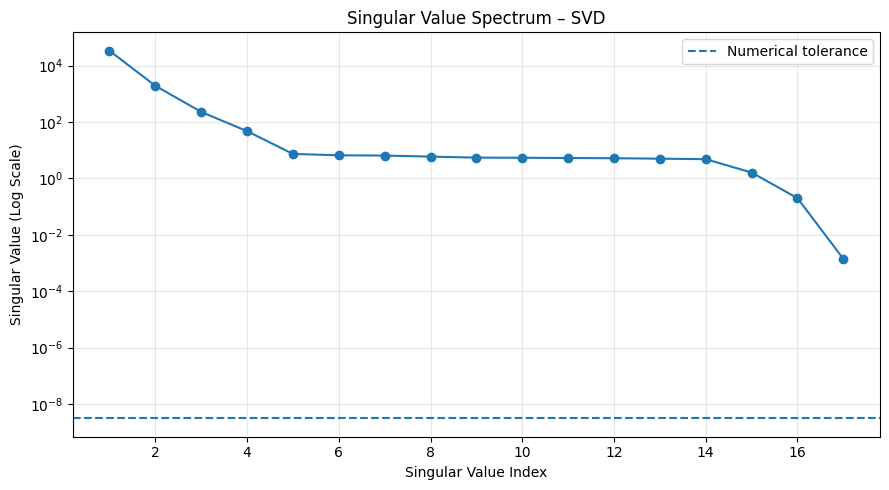

In [25]:
# Singular value spectrum

plt.figure(figsize=(9, 5))

plt.semilogy(
    np.arange(1, len(singular_values) + 1),
    singular_values,
    marker="o"
)

plt.axhline(
    y=svd_tolerance,
    linestyle="--",
    label="Numerical tolerance"
)

plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.title("Singular Value Spectrum – SVD")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

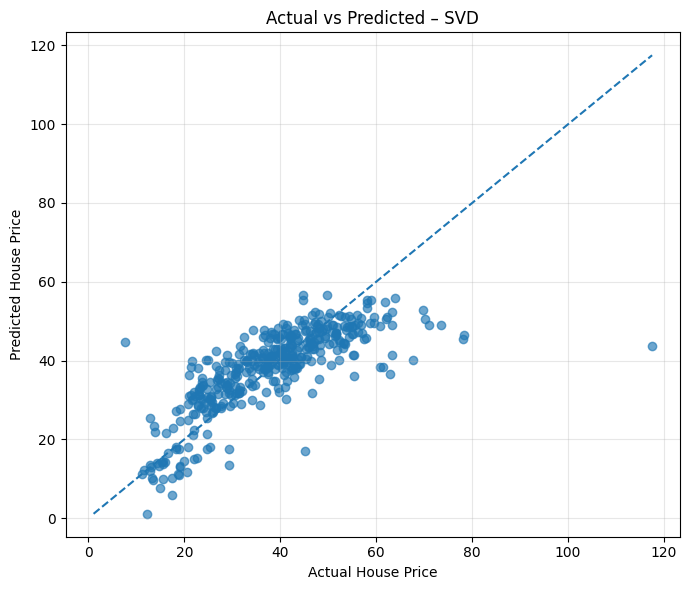

In [26]:
# actual vs predicted

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    y_pred_svd,
    alpha=0.65
)

lower = min(y.min(), y_pred_svd.min())
upper = max(y.max(), y_pred_svd.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

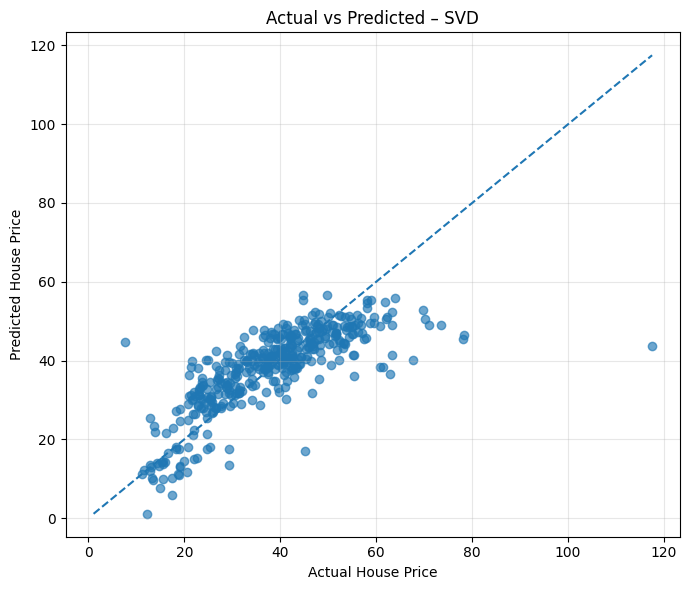

In [27]:
# residuals vs predicted

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    y_pred_svd,
    alpha=0.65
)

lower = min(y.min(), y_pred_svd.min())
upper = max(y.max(), y_pred_svd.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

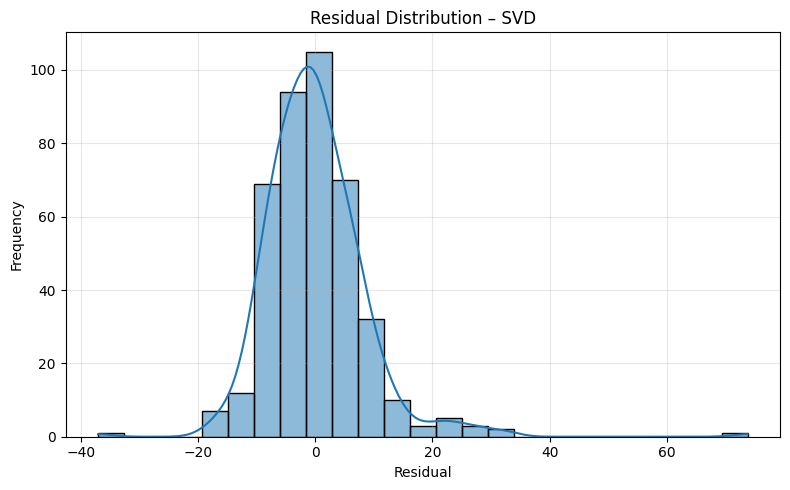

In [28]:
# residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals_svd,
    bins=25,
    kde=True
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Numerical Diagnostics Summary

This section consolidates the regression performance and numerical stability measures obtained from the SVD-based OLS implementation.

The summary provides a compact record of the model's predictive performance, matrix conditioning, numerical rank, decomposition accuracy and validation results.


In [29]:
diagnostics_svd = pd.DataFrame({
    "Diagnostic": [
        "Number of observations",
        "Number of design matrix columns",
        "Matrix rank",
        "Rank deficiency",
        "Condition number of X",
        "Condition number of X.T @ X",
        "Largest singular value",
        "Smallest singular value",
        "Numerical tolerance",
        "Reconstruction error",
        "U orthogonality error",
        "V orthogonality error",
        "Residual norm",
        "Relative residual",
        "Least-squares optimality error",
        "Pseudoinverse coefficient difference",
        "Pseudoinverse prediction difference",
        "NumPy coefficient difference",
        "NumPy prediction difference",
        "NumPy pseudoinverse difference"
    ],

    "Value": [
        x_design.shape[0],
        x_design.shape[1],
        rank_svd,
        rank_deficiency_svd,
        condition_x_svd,
        condition_xtx_svd,
        singular_values[0],
        singular_values[-1],
        svd_tolerance,
        reconstruction_error_svd,
        orthogonality_error_U,
        orthogonality_error_V,
        residual_norm_svd,
        relative_residual_svd,
        optimality_error_svd,
        pseudoinverse_coefficient_difference,
        pseudoinverse_prediction_difference,
        coefficient_difference_svd,
        prediction_difference_svd,
        pseudoinverse_numpy_difference
    ]
})

display(diagnostics_svd)

,Diagnostic,Value
0,Number of observations,4.140000e+02
1,Number of design matrix columns,1.700000e+01
2,Matrix rank,1.700000e+01
3,Rank deficiency,0.000000e+00
4,Condition number of X,2.384011e+07
5,Condition number of X.T @ X,5.683462e+14
6,Largest singular value,3.386772e+04
7,Smallest singular value,1.420619e-03
8,Numerical tolerance,3.113340e-09
9,Reconstruction error,1.698658e-11



## Final Results and Export

All numerical outputs and diagnostic figures generated in this notebook are saved to the designated results directory.

The exported files include regression coefficients, predictions, residuals, evaluation metrics, numerical diagnostics, singular values, pseudoinverse tolerance analysis and graphical visualizations.

Existing files with identical names are overwritten when the notebook is executed again.


In [30]:
# 1. Regression coefficients

coefficients_svd.to_csv(
    tables / "ols_svd_coefficients.csv",
    index=False
)


# 2. Predictions and residuals

predictions_svd = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred_svd,
    "Residual": residuals_svd
})

predictions_svd.to_csv(
    tables / "ols_svd_predictions.csv",
    index=False
)


# 3. Regression metrics

metrics_svd.to_csv(
    tables / "ols_svd_metrics.csv",
    index=False
)


# 4. Numerical diagnostics

diagnostics_svd.to_csv(
    tables / "ols_svd_diagnostics.csv",
    index=False
)


# 5. NumPy validation

coefficient_comparison_svd.to_csv(
    tables / "ols_svd_numpy_validation.csv",
    index=False
)


# 6. Singular values

singular_values_table_svd = pd.DataFrame({
    "Singular Value Index": np.arange(
        1,
        len(singular_values) + 1
    ),
    "Singular Value": singular_values
})

singular_values_table_svd.to_csv(
    tables / "ols_svd_singular_values.csv",
    index=False
)


# 7. Pseudoinverse tolerance sensitivity

tolerance_sensitivity.to_csv(
    tables / "ols_svd_tolerance_sensitivity.csv",
    index=False
)


# 8. Feature names

pd.DataFrame({
    "Feature": feature_names
}).to_csv(
    tables / "ols_svd_feature_names.csv",
    index=False
)


# 9. Pseudoinverse coefficient estimates

pseudoinverse_coefficients_svd = pd.DataFrame({
    "Feature": feature_names,
    "Pseudoinverse Coefficient": beta_pseudoinverse
})

pseudoinverse_coefficients_svd.to_csv(
    tables / "ols_svd_pseudoinverse_coefficients.csv",
    index=False
)

print("All SVD numerical results exported successfully.")

All SVD numerical results exported successfully.


In [31]:
# Figure 1: Singular value spectrum

plt.figure(figsize=(9, 5))

plt.semilogy(
    np.arange(1, len(singular_values) + 1),
    singular_values,
    marker="o"
)

plt.axhline(
    y=svd_tolerance,
    linestyle="--",
    label="Numerical tolerance"
)

plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.title("Singular Value Spectrum – SVD")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures / "ols_svd_singular_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Figure 2: Actual vs predicted

plt.figure(figsize=(7, 6))

plt.scatter(y, y_pred_svd, alpha=0.65)

lower = min(y.min(), y_pred_svd.min())
upper = max(y.max(), y_pred_svd.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures / "ols_svd_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Figure 3: Residuals vs predicted

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_svd,
    residuals_svd,
    alpha=0.65
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures / "ols_svd_residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Figure 4: Residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals_svd,
    bins=25,
    kde=True
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution – SVD")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures / "ols_svd_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("All SVD figures exported successfully.")

All SVD figures exported successfully.
